# HV-012 — Monte Carlo Uncertainty

**Technical gate:** MC-001  
**Analytical baseline:** HV-011 / MU-001

This notebook validates the analytical uncertainty propagation and then tests sensitivity to the observed finite Direction × Run state structure.

## 1. Engineering Question

> Does Monte Carlo propagation reproduce the HV-011 analytical uncertainty budget, and how does distribution shape change when the point-state component is represented by the observed Direction × Run support instead of a Gaussian approximation?

Two frozen models are used:

- **Model A:** analytical-equivalent Gaussian state component;
- **Model B:** variance-matched empirical state bootstrap.

## 2. Reproducible Setup

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

current_dir = Path.cwd()
candidate_roots = [current_dir, *current_dir.parents]

project_root = next(
    (
        path
        for path in candidate_roots
        if (path / "reports" / "tables" / "hv011_uncertainty_summary.csv").exists()
    ),
    None,
)

if project_root is None:
    raise FileNotFoundError(
        "Could not locate project root containing HV-011 uncertainty evidence."
    )

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.monte_carlo_analysis import (
    MonteCarloConfig,
    build_empirical_state_support,
    build_model_comparison,
    load_hv011_inputs,
    run_monte_carlo,
    validate_mc_gate,
)

tables_dir = project_root / "reports" / "tables"
figures_dir = project_root / "reports" / "figures"
tables_dir.mkdir(parents=True, exist_ok=True)
figures_dir.mkdir(parents=True, exist_ok=True)

mc_config = MonteCarloConfig(seed=7140, trials=250_000)

print(f"Project root: {project_root}")
print(f"Monte Carlo seed: {mc_config.seed}")
print(f"Trials per point per model: {mc_config.trials:,}")

Project root: /home/runner/work/hvac-sensor-validation-metrology/hvac-sensor-validation-metrology
Monte Carlo seed: 7140
Trials per point per model: 250,000


## 3. MC-01 — HV-011 Input Audit

HV-012 consumes only curated HV-011 analyst-visible evidence.

Expected:

- four evaluation points;
- four uncertainty components per point;
- four Test_ID state observations per point.

In [2]:
hv011_summary_df, hv011_budget_df, hv011_evidence_df = load_hv011_inputs(
    project_root
)

assert hv011_summary_df["Point_ID"].nunique() == 4
assert len(hv011_summary_df) == 4
assert len(hv011_budget_df) == 20
assert (
    hv011_evidence_df.groupby("Point_ID").size().eq(4).all()
)

print("HV-011 point summary")
display(
    hv011_summary_df[
        [
            "Point_ID",
            "RH_Percent",
            "Temperature_C",
            "Point_Residual_Bias",
            "U_State",
            "Combined_Standard_Uncertainty",
            "Expanded_Uncertainty",
        ]
    ].round(6)
)

print("MC-01 HV-011 input audit: PASS")

HV-011 point summary


,Point_ID,RH_Percent,Temperature_C,Point_Residual_Bias,U_State,Combined_Standard_Uncertainty,Expanded_Uncertainty
0,UNC-001,30.0,25.0,0.089179,0.502743,0.616533,1.233066
1,UNC-002,50.0,25.0,0.227137,0.473462,0.592898,1.185796
2,UNC-003,70.0,25.0,0.172012,0.473969,0.593303,1.186607
3,UNC-004,80.0,35.0,-0.157738,0.497799,0.612508,1.225016


MC-01 HV-011 input audit: PASS


## 4. MC-02 — Empirical State Support

For Model B, the four observed Test_ID residual means at each point are:

1. centered by subtracting the point mean;
2. rescaled to match the frozen HV-011 `u_state`;
3. sampled with equal probability.

This preserves the observed UP/DOWN and Run state pattern while keeping the same variance budget.

In [3]:
mc_state_support_df = build_empirical_state_support(
    hv011_summary_df,
    hv011_evidence_df,
)

support_audit = (
    mc_state_support_df
    .groupby("Point_ID")
    .agg(
        N_States=("MC_State_Support", "size"),
        Support_Mean=("MC_State_Support", "mean"),
        Support_Pop_SD=(
            "MC_State_Support",
            lambda x: np.std(x.to_numpy(dtype=float), ddof=0),
        ),
        Target_U_State=("Target_U_State", "first"),
    )
    .reset_index()
)

assert (support_audit["N_States"] == 4).all()
assert np.allclose(support_audit["Support_Mean"], 0.0, atol=1e-12)
assert np.allclose(
    support_audit["Support_Pop_SD"],
    support_audit["Target_U_State"],
    rtol=1e-12,
    atol=1e-12,
)

display(mc_state_support_df.round(6))
print("State-support audit")
display(support_audit.round(6))

print("MC-02 empirical state support: PASS")

,Point_ID,Test_ID,Direction,Run_ID,Original_C1_MBE,Original_Centered_State,State_Scale_Factor,MC_State_Support,Target_U_State
0,UNC-001,VAL-005,UP,1,-0.286488,-0.375667,1.152150,-0.432824,0.502743
1,UNC-001,VAL-006,UP,2,-0.398821,-0.488000,1.152150,-0.562249,0.502743
2,UNC-001,VAL-007,DOWN,1,0.589512,0.500333,1.152150,0.576459,0.502743
3,UNC-001,VAL-008,DOWN,2,0.452512,0.363333,1.152150,0.418614,0.502743
4,UNC-002,VAL-017,UP,1,-0.155655,-0.382792,1.151826,-0.440909,0.473462
5,UNC-002,VAL-018,UP,2,-0.206655,-0.433792,1.151826,-0.499652,0.473462
6,UNC-002,VAL-019,DOWN,1,0.697679,0.470542,1.151826,0.541982,0.473462
7,UNC-002,VAL-020,DOWN,2,0.573179,0.346042,1.151826,0.398580,0.473462
8,UNC-003,VAL-029,UP,1,-0.200988,-0.373000,1.151832,-0.429633,0.473969
9,UNC-003,VAL-030,UP,2,-0.268155,-0.440167,1.151832,-0.506998,0.473969


State-support audit


,Point_ID,N_States,Support_Mean,Support_Pop_SD,Target_U_State
0,UNC-001,4,-0.0,0.502743,0.502743
1,UNC-002,4,0.0,0.473462,0.473462
2,UNC-003,4,-0.0,0.473969,0.473969
3,UNC-004,4,-0.0,0.497799,0.497799


MC-02 empirical state support: PASS


## 5. MC-03 — Run Frozen Monte Carlo Models

Common components:

```text
Repeatability ~ Normal(0, u_repeat_mean)
C1 estimate   ~ Normal(0, u_C1)
Reference     ~ Normal(0, u_ref_cal)
Stability     ~ Uniform(-a_stability, +a_stability)
```

State component:

```text
Model A: Normal(0, u_state)
Model B: variance-matched empirical bootstrap
```

In [4]:
mc_summary_df, mc_samples = run_monte_carlo(
    summary_df=hv011_summary_df,
    state_support_df=mc_state_support_df,
    config=mc_config,
)

assert len(mc_summary_df) == 8
assert set(mc_summary_df["Model"]) == {
    "A_ANALYTICAL_EQUIVALENT",
    "B_EMPIRICAL_STATE",
}

display(
    mc_summary_df[
        [
            "Point_ID",
            "Model",
            "MC_Mean",
            "MC_SD",
            "Relative_SD_Error_vs_Analytical",
            "Q025",
            "Median",
            "Q975",
            "Coverage_Inside_PlusMinus_2uc",
            "Skewness",
            "Excess_Kurtosis",
        ]
    ].round(6)
)

print("MC-03 frozen Monte Carlo models executed: PASS")

,Point_ID,Model,MC_Mean,MC_SD,Relative_SD_Error_vs_Analytical,Q025,Median,Q975,Coverage_Inside_PlusMinus_2uc,Skewness,Excess_Kurtosis
0,UNC-001,A_ANALYTICAL_EQUIVALENT,-0.000003,0.616755,0.000361,-1.206314,-0.000855,1.205244,0.955168,0.000936,-0.055449
1,UNC-001,B_EMPIRICAL_STATE,-0.001726,0.616527,-0.000009,-1.086523,-0.004632,1.092323,0.984116,0.010529,-0.910853
2,UNC-002,A_ANALYTICAL_EQUIVALENT,0.000546,0.592270,-0.001059,-1.158203,-0.000222,1.159754,0.955072,0.004570,-0.049416
3,UNC-002,B_EMPIRICAL_STATE,-0.000986,0.592035,-0.001455,-1.051018,-0.004736,1.057220,0.982232,0.016531,-0.860772
4,UNC-003,A_ANALYTICAL_EQUIVALENT,0.001582,0.592318,-0.001661,-1.156166,0.001144,1.156628,0.955900,-0.003055,-0.067453
5,UNC-003,B_EMPIRICAL_STATE,-0.000096,0.593050,-0.000428,-1.050630,-0.005471,1.068301,0.981496,0.023505,-0.849942
6,UNC-004,A_ANALYTICAL_EQUIVALENT,-0.000685,0.612496,-0.000020,-1.199850,-0.000616,1.198327,0.954940,-0.000972,-0.062828
7,UNC-004,B_EMPIRICAL_STATE,-0.000405,0.612319,-0.000308,-1.092333,0.006420,1.076981,0.983152,-0.018402,-0.894003


MC-03 frozen Monte Carlo models executed: PASS


## 6. MC-04 — Numerical Validation Checks

Frozen tolerances:

### Model A

```text
|MC_SD - analytical u_c| / u_c <= 1%
|MC_Mean| <= 0.01 %RH
```

### Model B

```text
|MC_SD - analytical u_c| / u_c <= 1.5%
|MC_Mean| <= 0.01 %RH
```

Model B is not required to reproduce Gaussian interval shape.

In [5]:
mc_gate_checks_df = validate_mc_gate(mc_summary_df)

display(mc_gate_checks_df)

assert mc_gate_checks_df["Gate_Check_PASS"].all()

model_a_checks = mc_gate_checks_df.loc[
    mc_gate_checks_df["Model"].eq("A_ANALYTICAL_EQUIVALENT")
]
model_b_checks = mc_gate_checks_df.loc[
    mc_gate_checks_df["Model"].eq("B_EMPIRICAL_STATE")
]

assert len(model_a_checks) == 4
assert len(model_b_checks) == 4

print("MC-04 numerical variance/centering validation: PASS")

,Point_ID,Model,Mean_Abs_Limit,Mean_Abs_Observed,Mean_Check_PASS,Relative_SD_Error_Limit,Relative_SD_Error_Abs,SD_Check_PASS,Gate_Check_PASS
0,UNC-001,A_ANALYTICAL_EQUIVALENT,0.01,0.000003,True,0.010,0.000361,True,True
1,UNC-001,B_EMPIRICAL_STATE,0.01,0.001726,True,0.015,0.000009,True,True
2,UNC-002,A_ANALYTICAL_EQUIVALENT,0.01,0.000546,True,0.010,0.001059,True,True
3,UNC-002,B_EMPIRICAL_STATE,0.01,0.000986,True,0.015,0.001455,True,True
4,UNC-003,A_ANALYTICAL_EQUIVALENT,0.01,0.001582,True,0.010,0.001661,True,True
5,UNC-003,B_EMPIRICAL_STATE,0.01,0.000096,True,0.015,0.000428,True,True
6,UNC-004,A_ANALYTICAL_EQUIVALENT,0.01,0.000685,True,0.010,0.000020,True,True
7,UNC-004,B_EMPIRICAL_STATE,0.01,0.000405,True,0.015,0.000308,True,True


MC-04 numerical variance/centering validation: PASS


## 7. MC-05 — Analytical Interval vs Monte Carlo Distribution

The analytical HV-011 interval is:

```text
± 2 u_c
```

This section compares it with the actual central 95% Monte Carlo interval under both distribution models.

In [6]:
mc_model_comparison_df = build_model_comparison(mc_summary_df)

display(mc_model_comparison_df.round(6))

print("MC-05 analytical/Monte Carlo interval comparison: PASS")

,Point_ID,Analytical_uc,ModelA_MC_SD,ModelB_MC_SD,ModelA_Central95_HalfWidth,ModelB_Central95_HalfWidth,ModelA_Coverage_Inside_2uc,ModelB_Coverage_Inside_2uc,ModelA_Skewness,ModelB_Skewness,ModelA_Excess_Kurtosis,ModelB_Excess_Kurtosis,ModelB_vs_A_95HalfWidth_Ratio
0,UNC-001,0.616533,0.616755,0.616527,1.205779,1.089423,0.955168,0.984116,0.000936,0.010529,-0.055449,-0.910853,0.903502
1,UNC-002,0.592898,0.592270,0.592035,1.158979,1.054119,0.955072,0.982232,0.004570,0.016531,-0.049416,-0.860772,0.909524
2,UNC-003,0.593303,0.592318,0.593050,1.156397,1.059466,0.955900,0.981496,-0.003055,0.023505,-0.067453,-0.849942,0.916178
3,UNC-004,0.612508,0.612496,0.612319,1.199089,1.084657,0.954940,0.983152,-0.000972,-0.018402,-0.062828,-0.894003,0.904568


MC-05 analytical/Monte Carlo interval comparison: PASS


## 8. MC-06 — Residual Bias Kept Separate

Consistent with HV-011, Monte Carlo uncertainty error is centered at zero.

For descriptive total-error envelopes only:

```text
Total_Error = Point_Residual_Bias + MC_Uncertainty_Error
```

No residual-bias correction is introduced here.

In [7]:
total_error_rows = []

for _, row in mc_summary_df.iterrows():
    point_id = row["Point_ID"]
    model = row["Model"]
    bias = float(row["Point_Residual_Bias"])
    values = mc_samples[(point_id, model)] + bias

    q025, q50, q975 = np.quantile(values, [0.025, 0.50, 0.975])

    total_error_rows.append(
        {
            "Point_ID": point_id,
            "Model": model,
            "Residual_Bias": bias,
            "Total_Error_Q025": q025,
            "Total_Error_Median": q50,
            "Total_Error_Q975": q975,
            "Probability_Within_Public_Static_Accuracy_Limit": np.mean(
                np.abs(values) <= 2.0
            ),
        }
    )

mc_total_error_df = pd.DataFrame(total_error_rows)

display(mc_total_error_df.round(6))

print("MC-06 residual-bias separation: PASS")

,Point_ID,Model,Residual_Bias,Total_Error_Q025,Total_Error_Median,Total_Error_Q975,Probability_Within_Public_Static_Accuracy_Limit
0,UNC-001,A_ANALYTICAL_EQUIVALENT,0.089179,-1.117135,0.088324,1.294423,0.998964
1,UNC-001,B_EMPIRICAL_STATE,0.089179,-0.997344,0.084547,1.181502,1.000000
2,UNC-002,A_ANALYTICAL_EQUIVALENT,0.227137,-0.931066,0.226915,1.386891,0.998664
3,UNC-002,B_EMPIRICAL_STATE,0.227137,-0.823881,0.222402,1.284357,0.999992
4,UNC-003,A_ANALYTICAL_EQUIVALENT,0.172012,-0.984153,0.173157,1.328640,0.999092
5,UNC-003,B_EMPIRICAL_STATE,0.172012,-0.878618,0.166542,1.240313,1.000000
6,UNC-004,A_ANALYTICAL_EQUIVALENT,-0.157738,-1.357588,-0.158354,1.040589,0.998776
7,UNC-004,B_EMPIRICAL_STATE,-0.157738,-1.250071,-0.151318,0.919243,1.000000


MC-06 residual-bias separation: PASS


## 9. MC-07 — Distribution-Shape Interpretation Diagnostics

Model A should be close to symmetric with a central 95% half-width near, but not necessarily equal to, `2u_c`.

Model B preserves four finite Direction × Run states. Its variance is matched to HV-011, but its tails may be materially different.

This is the key distinction:

```text
same variance does not imply same coverage interval
```

In [8]:
shape_diagnostics_df = mc_summary_df[
    [
        "Point_ID",
        "Model",
        "Analytical_2uc",
        "Central95_Symmetric_HalfWidth",
        "Coverage_Inside_PlusMinus_2uc",
        "Skewness",
        "Excess_Kurtosis",
    ]
].copy()

shape_diagnostics_df["MC95_to_Analytical2uc_Ratio"] = (
    shape_diagnostics_df["Central95_Symmetric_HalfWidth"]
    / shape_diagnostics_df["Analytical_2uc"]
)

display(shape_diagnostics_df.round(6))

print("MC-07 distribution-shape diagnostics: PASS")

,Point_ID,Model,Analytical_2uc,Central95_Symmetric_HalfWidth,Coverage_Inside_PlusMinus_2uc,Skewness,Excess_Kurtosis,MC95_to_Analytical2uc_Ratio
0,UNC-001,A_ANALYTICAL_EQUIVALENT,1.233066,1.205779,0.955168,0.000936,-0.055449,0.977870
1,UNC-001,B_EMPIRICAL_STATE,1.233066,1.089423,0.984116,0.010529,-0.910853,0.883507
2,UNC-002,A_ANALYTICAL_EQUIVALENT,1.185796,1.158979,0.955072,0.004570,-0.049416,0.977384
3,UNC-002,B_EMPIRICAL_STATE,1.185796,1.054119,0.982232,0.016531,-0.860772,0.888955
4,UNC-003,A_ANALYTICAL_EQUIVALENT,1.186607,1.156397,0.955900,-0.003055,-0.067453,0.974541
5,UNC-003,B_EMPIRICAL_STATE,1.186607,1.059466,0.981496,0.023505,-0.849942,0.892853
6,UNC-004,A_ANALYTICAL_EQUIVALENT,1.225016,1.199089,0.954940,-0.000972,-0.062828,0.978835
7,UNC-004,B_EMPIRICAL_STATE,1.225016,1.084657,0.983152,-0.018402,-0.894003,0.885423


MC-07 distribution-shape diagnostics: PASS


## 10. Curated Figures

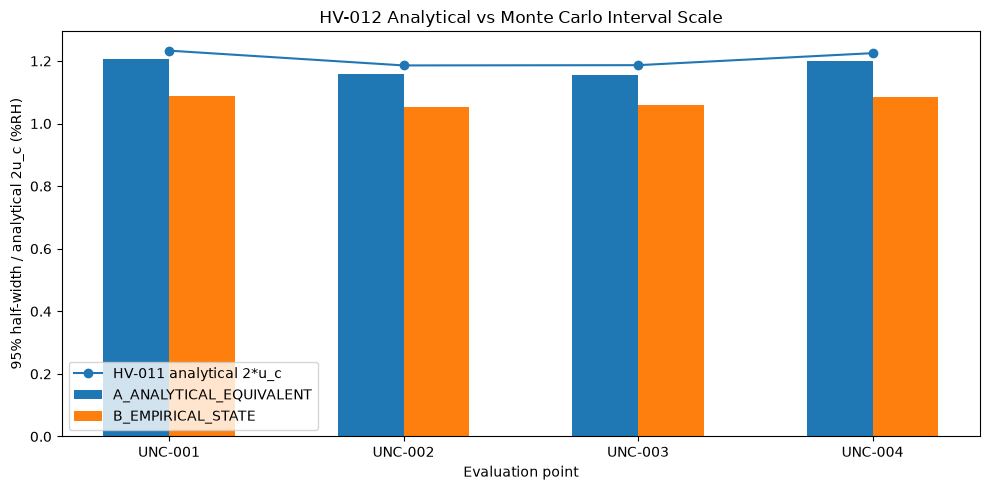

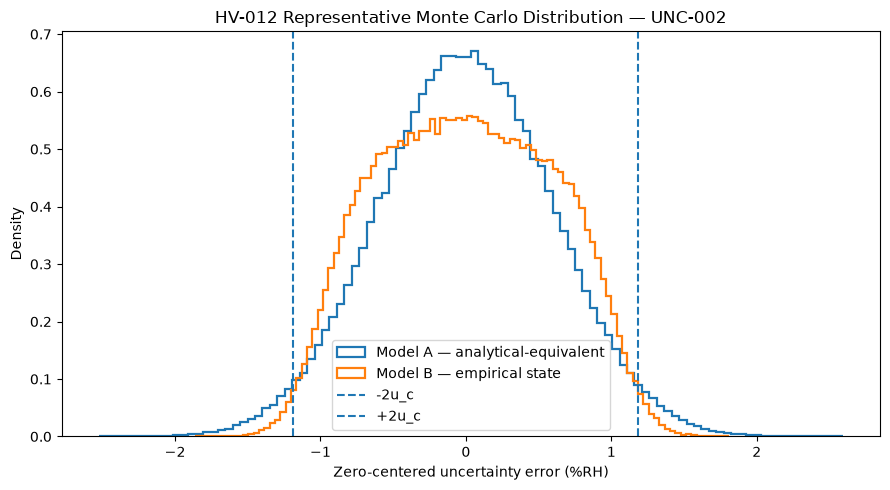

Curated HV-012 figures exported.


In [9]:
# Central-95 half-width compared with analytical 2*u_c
plot_df = mc_summary_df.copy()

fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(hv011_summary_df["Point_ID"].nunique())
width = 0.28

for j, model in enumerate(
    ["A_ANALYTICAL_EQUIVALENT", "B_EMPIRICAL_STATE"]
):
    g = (
        plot_df.loc[plot_df["Model"].eq(model)]
        .sort_values("Point_ID")
    )
    ax.bar(
        x + (j - 0.5) * width,
        g["Central95_Symmetric_HalfWidth"],
        width=width,
        label=model,
    )

analytical = (
    plot_df.loc[
        plot_df["Model"].eq("A_ANALYTICAL_EQUIVALENT")
    ]
    .sort_values("Point_ID")
)

ax.plot(
    x,
    analytical["Analytical_2uc"],
    marker="o",
    label="HV-011 analytical 2*u_c",
)

ax.set_xticks(x)
ax.set_xticklabels(analytical["Point_ID"])
ax.set_ylabel("95% half-width / analytical 2u_c (%RH)")
ax.set_xlabel("Evaluation point")
ax.set_title("HV-012 Analytical vs Monte Carlo Interval Scale")
ax.legend()
fig.tight_layout()
fig.savefig(
    figures_dir / "hv012_mc_interval_comparison.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

# Representative point distribution: UNC-002
point_id = "UNC-002"
a_values = mc_samples[(point_id, "A_ANALYTICAL_EQUIVALENT")]
b_values = mc_samples[(point_id, "B_EMPIRICAL_STATE")]

fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(
    a_values,
    bins=100,
    density=True,
    histtype="step",
    linewidth=1.6,
    label="Model A — analytical-equivalent",
)
ax.hist(
    b_values,
    bins=100,
    density=True,
    histtype="step",
    linewidth=1.6,
    label="Model B — empirical state",
)

u_c_rep = float(
    hv011_summary_df.loc[
        hv011_summary_df["Point_ID"].eq(point_id),
        "Combined_Standard_Uncertainty",
    ].iloc[0]
)
ax.axvline(-2.0 * u_c_rep, linestyle="--", label="-2u_c")
ax.axvline(+2.0 * u_c_rep, linestyle="--", label="+2u_c")

ax.set_xlabel("Zero-centered uncertainty error (%RH)")
ax.set_ylabel("Density")
ax.set_title("HV-012 Representative Monte Carlo Distribution — UNC-002")
ax.legend()
fig.tight_layout()
fig.savefig(
    figures_dir / "hv012_mc_representative_distribution.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

print("Curated HV-012 figures exported.")

## 11. Curated Evidence Export

In [10]:
mc_summary_df.to_csv(
    tables_dir / "hv012_mc_summary.csv",
    index=False,
)
mc_state_support_df.to_csv(
    tables_dir / "hv012_mc_state_support.csv",
    index=False,
)
mc_model_comparison_df.to_csv(
    tables_dir / "hv012_mc_model_comparison.csv",
    index=False,
)

print("Curated HV-012 tables exported.")

Curated HV-012 tables exported.


## 12. Initial MC-001 Checkpoint

A clean-kernel Run All should establish:

- MC-01 HV-011 input audit PASS;
- MC-02 empirical-state support PASS;
- MC-03 both frozen models executed;
- MC-04 numerical variance/centering validation PASS;
- MC-05 analytical/MC interval comparison PASS;
- MC-06 residual-bias separation PASS;
- MC-07 distribution-shape diagnostics PASS;
- three curated CSV tables;
- two curated figures.

The next step is engineering interpretation and formal MC-001 gate closure.

## 13. Engineering Interpretation

### 13.1 Model A validates the HV-011 analytical uncertainty propagation

Model A was designed to reproduce the same component variances used by HV-011.

Across all four points, Monte Carlo standard deviation agrees with analytical `u_c` extremely closely:

```text
UNC-001: relative SD error ≈ +0.036 %
UNC-002: relative SD error ≈ -0.106 %
UNC-003: relative SD error ≈ -0.166 %
UNC-004: relative SD error ≈ -0.002 %
```

All are far inside the frozen ±1% criterion.

Monte Carlo means are also close to zero:

```text
|mean| <= 0.00159 %RH
```

Therefore the HV-011 root-sum-of-squares implementation is numerically validated.

### 13.2 Model A central 95% interval is close to, but not identical to, ±2u_c

Model A central 95% half-widths are approximately:

```text
UNC-001: 1.2058 %RH
UNC-002: 1.1590 %RH
UNC-003: 1.1564 %RH
UNC-004: 1.1991 %RH
```

HV-011 analytical `2u_c` values are approximately:

```text
UNC-001: 1.2331 %RH
UNC-002: 1.1858 %RH
UNC-003: 1.1866 %RH
UNC-004: 1.2250 %RH
```

Thus the analytical k=2 interval is slightly wider than the Model A Monte Carlo central 95% interval.

Coverage inside `±2u_c` is approximately:

```text
95.49–95.59 %
```

This is consistent with the mixed Normal + Uniform component model and confirms that using `k=2` is slightly conservative relative to the exact Model A central 95% interval.

### 13.3 Model B preserves variance but materially changes distribution shape

Model B Monte Carlo SD also agrees with analytical `u_c`:

```text
relative SD error magnitude <= 0.146 %
```

Therefore the empirical-state construction successfully preserves the HV-011 variance budget.

However, Model B central 95% half-widths are smaller:

```text
UNC-001: 1.0894 %RH
UNC-002: 1.0541 %RH
UNC-003: 1.0595 %RH
UNC-004: 1.0847 %RH
```

Compared with Model A, these are only about:

```text
90.4 %, 91.0 %, 91.6 %, and 90.5 %
```

of the Model A central-95 half-width.

Thus identical variance does **not** imply identical coverage interval.

### 13.4 The empirical-state model is strongly platykurtic

Model B excess kurtosis is approximately:

```text
-0.91, -0.86, -0.85, -0.89
```

while skewness remains near zero.

This reflects the finite, approximately balanced UP/DOWN state support combined with bounded stability variation.

The result is a flatter, more bounded-tail distribution than the Gaussian state approximation.

Coverage inside the analytical `±2u_c` interval rises to approximately:

```text
98.15–98.41 %
```

under Model B.

Within this **specific empirical-state sensitivity model**, the HV-011 k=2 interval is therefore conservative in coverage terms.

This must not be generalized into a field-population statement because only four Test_ID state observations are available per point.

### 13.5 Direction/Run structure matters beyond variance alone

The four empirical state supports remain visibly separated into negative UP states and positive DOWN states at all four points.

This confirms the earlier physical interpretation:

- the dominant uncertainty contribution is state/history dependence;
- that contribution is not naturally Gaussian in the available evidence;
- a single standard deviation captures its scale but not its structure.

The Monte Carlo analysis therefore adds information beyond the analytical budget by showing how the same variance can produce materially different tail behavior.

### 13.6 Residual-bias plus Monte Carlo total-error distributions remain well inside ±2 %RH in the static model

After adding the frozen point residual bias, Model A central 95% total-error intervals are approximately:

```text
UNC-001: [-1.109, +1.290] %RH
UNC-002: [-0.926, +1.376] %RH
UNC-003: [-0.981, +1.331] %RH
UNC-004: [-1.350, +1.039] %RH
```

Model B intervals are narrower.

The simulated probability of total error falling within the public static ±2 %RH accuracy limit is above 99.8% for all points under Model A and approximately 100% under Model B.

These probabilities are **model-based sensitivity results**, not formal compliance probabilities, because they depend on the assumed component distributions and limited empirical state support.

### 13.7 HV-011 analytical budget remains the primary uncertainty statement

HV-012 does not replace HV-011.

Instead:

```text
HV-011 = primary traceable analytical uncertainty budget
HV-012 = numerical validation + distribution-shape sensitivity
```

The primary reported uncertainty remains:

```text
u_c ≈ 0.593–0.617 %RH
U(k=2) ≈ 1.186–1.233 %RH
```

Monte Carlo validates the scale and demonstrates that distributional assumptions primarily affect tail/coverage interpretation rather than the combined standard uncertainty itself.

## 14. MC-001 Gate Decision

**MC-001 = PASS WITH DOCUMENTED CONDITIONS**

### Basis for PASS

- all frozen HV-011 inputs are reproduced correctly;
- seed and 250,000 trials per point/model are frozen;
- empirical state support is exactly zero-centered and variance-matched;
- Model A reproduces analytical `u_c` within 0.166% at worst, well inside the 1% gate;
- Model B reproduces analytical `u_c` within 0.146% at worst, well inside the 1.5% gate;
- Monte Carlo means satisfy the ±0.01 %RH centering criterion;
- analytical k=2 intervals are directly compared with MC central 95% intervals;
- distribution-shape diagnostics are explicit;
- residual bias remains separate;
- no hidden simulator truth is used.

### Documented conditions

1. **Limited empirical support:** Model B uses only four Test_ID state observations per evaluation point.
2. **Distribution assumption:** Model A treats reference calibration and point-state variability as Normal and observed stability excursion as Uniform.
3. **Empirical-state interpretation:** Model B is a structure-preserving sensitivity model, not an inferred population PDF.
4. **Coverage sensitivity:** `±2u_c` gives approximately 95.5% coverage in Model A but approximately 98.1–98.4% in Model B.
5. **Static scope:** the simulation applies to the HV-011 60-s stable static result only.
6. **No probabilistic compliance claim:** probability-within-±2 %RH results are model-dependent sensitivity diagnostics, not formal product reliability probabilities.

### Final MC conclusion

Monte Carlo confirms that the HV-011 analytical uncertainty scale is numerically sound.

The principal remaining uncertainty is not numerical propagation but **distributional/state modeling**, especially Direction dependence.

The next engineering stage is:

```text
HV-013 — Final Engineering Assessment
```